# Cs-137 ratio

> Predict the ratio of exchangeable to total Cs-137 from frozen layers of the OSSL Kex and CEC models, against PLSR and ridge regressions on the spectra

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import r2_score
from fastai.torch_core import set_seed
from ossl_fuku_transfer.data import *
from ossl_fuku_transfer.transfer import *
from ossl_fuku_transfer.inside import layer_features, probe

/Users/franckalbinet/pro/dev/soilspec/ossl-fuku-transfer/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Every code cell reads the Fukushima data or the saved OSSL models, and is marked `#| fukudata`.

## Target and scores

The target is the Cs137 study's `exCs137_totalCs137`: log10 of exchangeable over total Cs-137. `ratio_scores` gives R², correlation `r`, and the RMSE and bias, all on that log10 scale:

In [ ]:
#| fukudata
ref = fuku_path()/'reference'
csv = {s: pd.read_csv(ref/f'cs137_ratio_{s}.csv') for s in ('train', 'test')}
ratio = pd.concat(csv.values()).assign(ID=lambda d: d.ID.astype(str)).set_index('ID')['exCs137_totalCs137']
def ratio_scores(y, p): return {'R²': r2_score(y, p), 'r': np.corrcoef(y, p)[0, 1], 'RMSE': float(np.sqrt(np.mean((y - p)**2))), 'bias': float(np.mean(p - y))}
ratio.describe().round(3).to_dict()

{'count': 1592.0,
 'mean': -1.322,
 'std': 0.359,
 'min': -2.921,
 '25%': -1.563,
 '50%': -1.27,
 '75%': -1.044,
 'max': -0.606}

## The study's spectra

The Cs137 study's own spectra: 657 points from 685 to 3965 cm⁻¹, as exported for that study, with 1,194 training and 398 test samples. The current selection has `.spa` files for 1,388 of these samples: 1,047 training and 341 test samples. PLSR, with the number of components chosen by 5-fold cross-validation on the training samples, and a ridge regression, on the full split and on the samples of the current selection. This shows how much the smaller selection alone changes the scores:

In [ ]:
#| fukudata
def plsr(Xtr, ytr, Xte, yte, max_comp=60):
    "Test scores of PLSR with the number of components chosen by 5-fold cross-validation"
    gs = GridSearchCV(PLSRegression(scale=False), {'n_components': range(1, max_comp + 1)},
                      cv=KFold(5, shuffle=True, random_state=0), scoring='neg_mean_squared_error').fit(Xtr, ytr)
    return {**ratio_scores(yte, gs.predict(Xte).ravel()), 'components': gs.best_params_['n_components']}

sel = set(sample_ids())
study = {}
for name, keep in (('full split', lambda d: d), ('current selection', lambda d: d[d.ID.astype(str).isin(sel)])):
    tr, te = keep(csv['train']), keep(csv['test'])
    Xtr, Xte = tr.filter(regex='^X').to_numpy(), te.filter(regex='^X').to_numpy()
    ytr, yte = tr.exCs137_totalCs137.to_numpy(), te.exCs137_totalCs137.to_numpy()
    study[name, 'PLSR'] = {'n train': len(tr), 'n test': len(te), **plsr(Xtr, ytr, Xte, yte)}
    study[name, 'ridge'] = {'n train': len(tr), 'n test': len(te), **probe(Xtr, ytr, Xte, yte, score_fn=ratio_scores)}
pd.DataFrame(study).T.round(3)

n train  n test     R²  ...   bias  components   alpha
full split        PLSR    1194.0   398.0  0.543  ...  0.037        33.0     NaN
                  ridge   1194.0   398.0  0.544  ...  0.044         NaN  31.623
current selection PLSR    1048.0   341.0  0.558  ...  0.037        30.0     NaN
                  ridge   1048.0   341.0  0.555  ...  0.038         NaN  10.000

[4 rows x 8 columns]

## Spectra of the current selection

The `.spa` spectra on the shared 2 cm⁻¹ grid, with SNV and a Savitzky-Golay first derivative as in `03_kex`. Both steps work on each spectrum alone, so fitting them on Fukushima gives the same result as fitting them on OSSL. The same training and test samples as the current selection above:

In [ ]:
#| fukudata
fuku = load_fuku()
fuku.source = fuku.source.assign(target=ratio)
Xf, yf, idf = fuku.xy('target')
yf = yf.ravel()
is_test = np.isin(idf, cs137_split()[1])
Xf_d = preprocessings()['snv_d1'].fit_transform(Xf)
tr_, te_ = ~is_test, is_test
own = {'PLSR': plsr(Xf_d[tr_], yf[tr_], Xf_d[te_], yf[te_]), 'ridge': probe(Xf_d[tr_], yf[tr_], Xf_d[te_], yf[te_], score_fn=ratio_scores)}
int(tr_.sum()), int(te_.sum()), pd.DataFrame(own).T.round(3)

(1048,
 341,
           R²      r   RMSE   bias  components  alpha
 PLSR   0.560  0.757  0.229  0.038        23.0    NaN
 ridge  0.537  0.742  0.235  0.041         NaN  100.0)

## Frozen layers

Ridge regressions on each layer of three models, as in `07_inside_transfer`: the saved OSSL Kex and CEC models, and a model with random weights as a control. Neither OSSL model ever saw the Cs-137 ratio. The test R²:

In [ ]:
#| fukudata
set_seed(0)
models = {'OSSL Kex': load_pretrained('ossl_kex_snv_d1'), 'OSSL CEC': load_pretrained('ossl_cec_snv_d1'), 'random': new_model()}
F = {m: layer_features(model, Xf_d) for m, model in models.items()}
F['OSSL Kex + CEC'] = {k: np.hstack([F['OSSL Kex'][k], F['OSSL CEC'][k]]) for k in F['OSSL Kex'] if k != 'input'}
lay = pd.DataFrame({(m, k): probe(Fm[k][tr_], yf[tr_], Fm[k][te_], yf[te_], score_fn=ratio_scores) for m, Fm in F.items() for k in Fm}).T
lay['R²'].unstack(0).reindex(list(F['OSSL Kex'])).round(3)

,OSSL CEC,OSSL Kex,OSSL Kex + CEC,random
input,0.537,0.537,NaN,0.537
block 1,0.589,0.594,0.586,0.566
block 2,0.607,0.613,0.618,0.597
block 3,0.614,0.613,0.626,0.590
block 4,0.635,0.641,0.648,0.613
block 5,0.623,0.625,0.658,0.584
pooled,0.544,0.479,0.564,0.482


The correlation `r` of the same regressions:

In [ ]:
#| fukudata
lay['r'].unstack(0).reindex(list(F['OSSL Kex'])).round(3)

,OSSL CEC,OSSL Kex,OSSL Kex + CEC,random
input,0.742,0.742,NaN,0.742
block 1,0.776,0.779,0.776,0.761
block 2,0.788,0.792,0.792,0.778
block 3,0.794,0.791,0.797,0.778
block 4,0.801,0.805,0.811,0.789
block 5,0.795,0.796,0.814,0.773
pooled,0.745,0.706,0.760,0.702


## Learning curve

Ridge regressions on the spectra and on block 4 of each model, trained on random subsets of the training samples, five per size, and on all of them, and scored on the same test set:

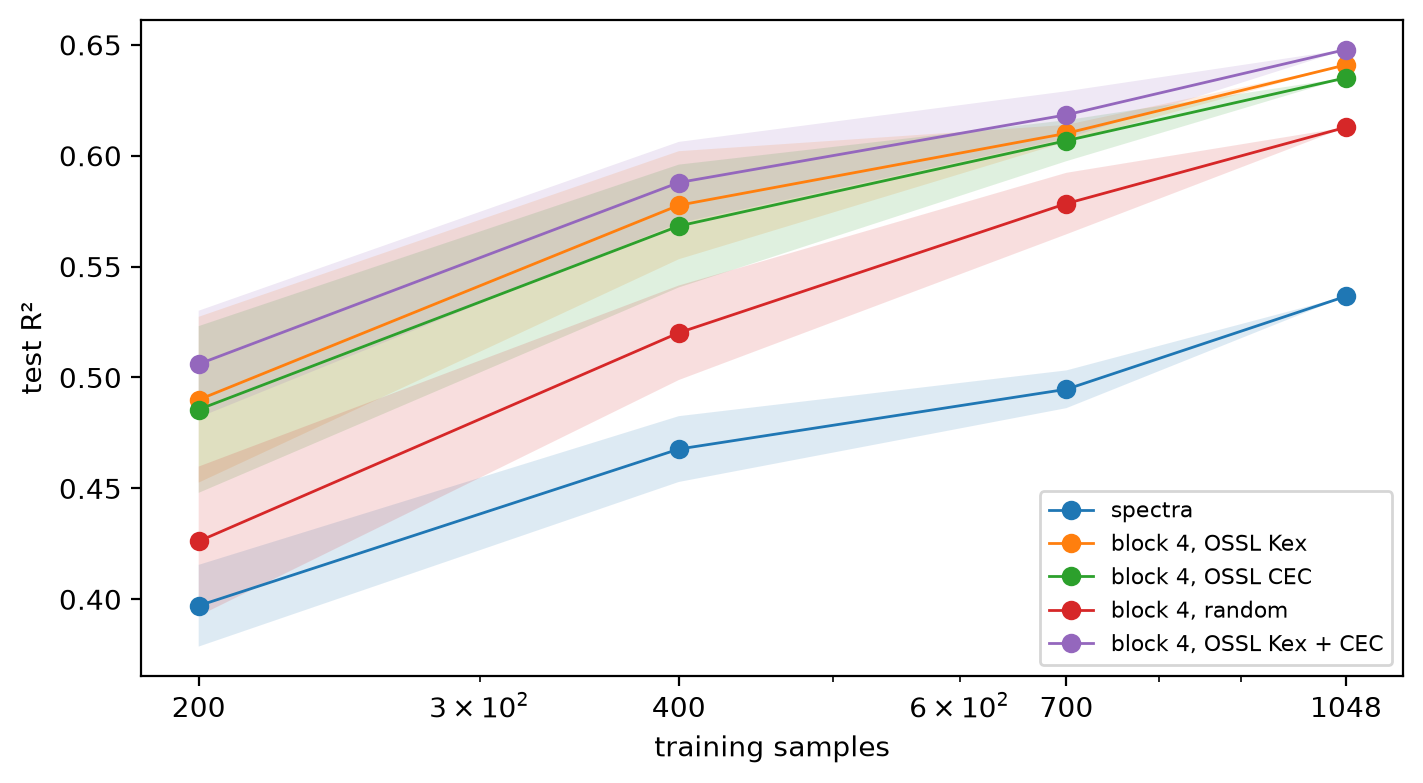

features,spectra,"block 4, OSSL Kex","block 4, OSSL CEC","block 4, random","block 4, OSSL Kex + CEC"
n,,,,,
200,0.397,0.490,0.486,0.426,0.506
400,0.468,0.578,0.568,0.520,0.588
700,0.495,0.610,0.607,0.578,0.618
1048,0.537,0.641,0.635,0.613,0.648


In [ ]:
#| fukudata
feats = {'spectra': Xf_d, **{f'block 4, {m}': F[m]['block 4'] for m in F}}
sizes, rows = [200, 400, 700, int(tr_.sum())], []
for n in sizes:
    for s in range(5):
        sub = np.random.RandomState(s).choice(np.flatnonzero(tr_), n, replace=False)
        for k, Fx in feats.items(): rows.append({'features': k, 'n': n, 'seed': s, **probe(Fx[sub], yf[sub], Fx[te_], yf[te_], score_fn=ratio_scores)})
lc = pd.DataFrame(rows).groupby(['features', 'n'], sort=False)['R²'].agg(['mean', 'std'])
fig, ax = plt.subplots(figsize=(7, 3.8), layout='constrained')
for k in feats:
    s = lc.loc[k]
    ax.plot(s.index, s['mean'], marker='o', lw=1, label=k)
    ax.fill_between(s.index, s['mean'] - s['std'], s['mean'] + s['std'], alpha=0.15)
ax.set_xscale('log'); ax.set_xticks(sizes, sizes); ax.set_xlabel('training samples'); ax.set_ylabel('test R²'); ax.legend(fontsize=8)
lc['mean'].unstack(0).round(3)

## Findings

Frozen layers of the OSSL models predict the Cs-137 ratio clearly better than the spectra. On the 341 test samples of the current selection, a ridge regression on block 4 of the OSSL Kex model gives a test R² of 0.64 (r 0.80), and on block 4 of the Kex and CEC models together 0.65 (r 0.81). The best layer is block 5 of the two models together, at 0.66 (r 0.81). On the same samples, PLSR on the `.spa` spectra gives 0.56 (r 0.76) and a ridge regression on them 0.54. Neither OSSL model was trained on the Cs-137 ratio.

Part of the gain comes from the architecture, not from OSSL. Block 4 of the model with random weights gives 0.61, against 0.64 for the OSSL Kex model. The OSSL features add most when the training samples are few: with 200 samples, block 4 gives 0.49 for the OSSL Kex model, 0.43 for the random model and 0.40 for the spectra. With all 1,048, they give 0.64, 0.61 and 0.54.

With 400 training samples, a ridge regression on block 4 of the OSSL models (0.57 to 0.59) beats a ridge regression on the spectra with all 1,048 (0.54). Like Kex in `08_learning_curve`, every set of features is still gaining at 1,048 samples, by 0.03 to 0.04 R² from 700 samples.

As for Kex, the pooled features transfer worst: 0.48 for the OSSL Kex model and 0.54 for the OSSL CEC model, no better than the spectra.

PLSR on the Cs137 study's own spectra gives 0.54 on its full split (1,194 training and 398 test samples) and 0.56 on the samples of the current selection. So the smaller selection doesn't lower the scores. These PLSR scores are below the R² of about 0.68 that the earlier study reported for PLSR and Cubist. That study's preprocessing and model settings are not reproduced here, so the comparison with it is not like for like.